## 6. Apprentissage d'un RNN sur le corpus de texte Victor HUGO

```
Objectif: Prédire le mot suivant à partir des 3 mots précédents, puis un texte mots après mot. Les exemples d'entraînement et la génération utilisent le même format: une fenétre de 3 mots, complétée par des zéros au début si besoin
```

In [6]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

In [7]:
with open('victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']
    
print(f"Exemple de texte: {texts[0]}")

Exemple de texte: Mes vers fuiraient


In [9]:
vocab = 1000
wondow_size = 3

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=vocab)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [14]:
X = []
y = []
window_size = 3

for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[max(0, i - window_size):i])
        y.append(seq[i])

X = tf.keras.preprocessing.sequence.pad_sequences(
    X, maxlen=window_size, padding="pre"
)
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)
X shape: (11541, 3), y shape: (11541,)


In [16]:
embedding_dim = 16

model = keras.Sequential([
    keras.layers.Embedding(input_dim=vocab, output_dim=embedding_dim),
    keras.layers.SimpleRNN(32),
    keras.layers.Dense(vocab, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="loss",
    patience=10,
    restore_best_weights=True
)
history = model.fit(
    X, y, 
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0335 - loss: 6.1388
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0365 - loss: 5.8512
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0459 - loss: 5.7514
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0495 - loss: 5.6394
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0577 - loss: 5.5441
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0600 - loss: 5.4595
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0644 - loss: 5.3871
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0729 - loss: 5.3175
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0781 - loss: 5.2510
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0849 - loss: 5.1852
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0914 - loss: 5.1148
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

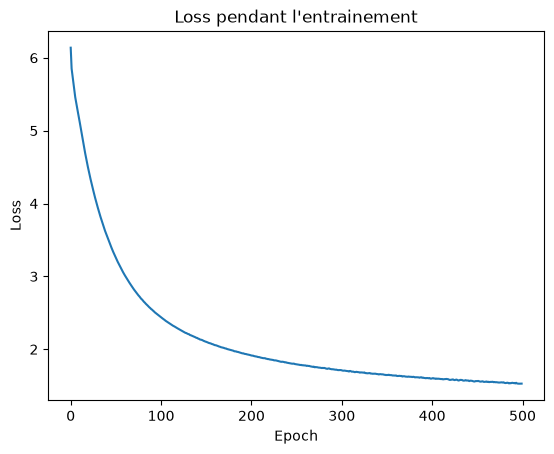

In [20]:
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entrainement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [22]:
def generate_text(start_text, num_words=50, temperature=0.80):
    text = start_text
    for _ in range(num_words):
        #même format qu'à l'entrainement: les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][window_size:]
        tokens = pad_sequences([tokens], maxlen=wondow_size, padding='pre')
        #probablities du mot suivant
        probs = model.predict(tokens, verbose=0)[0]
        #Tirage pondéré(temperature <1 : plus sûr, >1 : plus varié)
        probs = np.exp(np.log(probs + 1e-9) /temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)
        
        word = tokenizer.index_word.get(index)
        
        if word is not None:
            text += ' ' +word
            
    return text 

In [26]:
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème notre chasse vint les fleurs aux sont et ma et elle est aux le ange il regarde obscur plus flamme et si si belle fond des mers du soleil en jour un bon que le me sacré misère regard me autres voilà qui âme pour ses coeurs leur vol des
